In [5]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [7]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     4667 │        3633 │           3573 │      1155 │   13028 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 4667,
  'PNEUMONIA': 3633,
  'TUBERCULOSIS': 3573,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-03-11 07:52:33.902074: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-03-11 07:52:33.902106: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-03-11 07:52:33.902118: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-03-11 07:52:33.902585: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-03-11 07:52:33.902600: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [18]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


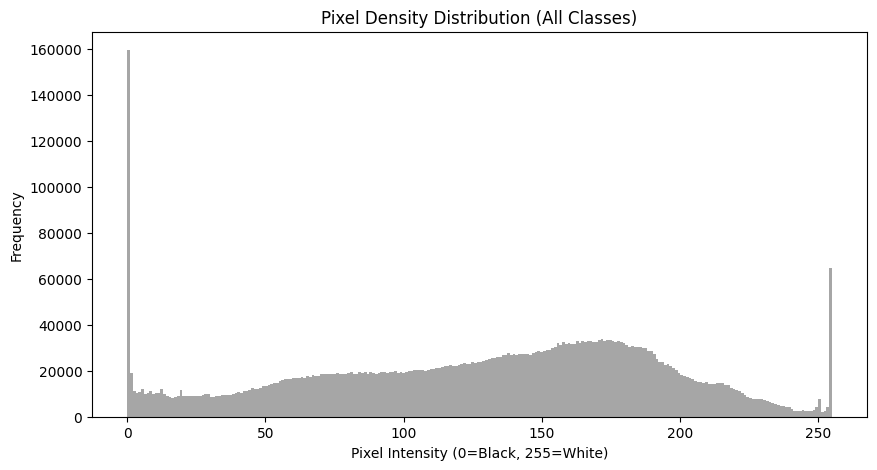

2026-03-11 07:52:43.815696: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (e.g., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

2026-03-11 07:52:51.355199: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


IndexError: list index out of range

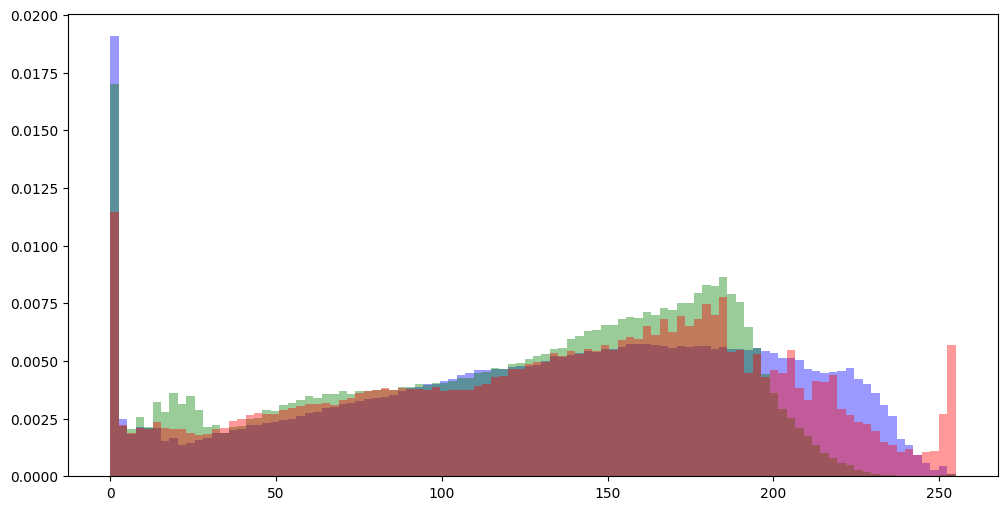

In [10]:
def plot_class_histograms(dataset, class_names):
    plt.figure(figsize=(12, 6))
    
    # Store pixels for each class
    class_pixels = {name: [] for name in class_names}
    
    # Analyze 5 batches for a good sample size
    for images, labels in dataset.take(5):
        images = images.numpy()
        labels = np.argmax(labels.numpy(), axis=1)
        
        for i in range(len(images)):
            cls_name = class_names[labels[i]]
            # Add flattened pixels of this specific image
            class_pixels[cls_name].extend(images[i].flatten())

    # Plotting
    colors = ['blue', 'green', 'red']
    for i, name in enumerate(class_names):
        plt.hist(class_pixels[name], bins=100, alpha=0.4, 
                 label=name, color=colors[i], density=True)

    plt.title('Pixel Density Comparison by Class')
    plt.xlabel('Intensity Value')
    plt.ylabel('Normalized Density')
    plt.legend()
    plt.show()

# Usage
plot_class_histograms(train_ds, train_ds.class_names)

In [11]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-03-11 07:53:17.948838: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 50s 119ms/step - accuracy: 0.7238 - loss: 0.8291 - val_accuracy: 0.8817 - val_loss: 0.4194
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 45s 109ms/step - accuracy: 0.8307 - loss: 0.5858 - val_accuracy: 0.8791 - val_loss: 0.4057
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 46s 113ms/step - accuracy: 0.8381 - loss: 0.6469 - val_accuracy: 0.8489 - val_loss: 0.4668
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 46s 113ms/step - accuracy: 0.8417 - loss: 0.7564 - val_accuracy: 0.9120 - val_loss: 0.4012
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 48s 116ms/step - accuracy: 0.8593 - loss: 0.5873 - val_accuracy: 0.8778 - val_loss: 0.7972
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 50s 121ms/step - accuracy: 0.8641 - loss: 0.7070 - val_accuracy: 0.8949 - val_loss: 1.5478
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 49s 119ms/step - accuracy: 0.8650 - loss: 0.9562 - val_accuracy: 0.8896 - val_loss: 0.8847
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - accuracy: 0.8709 - loss: 0.9475 - val

In [13]:
# Save the model
model.save('CXC103.keras')
print("Model saved successfully!")

Model saved successfully!


In [14]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9175 - loss: 1.3894
Test Loss: 1.3894418478012085
Test Accuracy: 91.75%


2026-03-11 08:02:35.913228: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


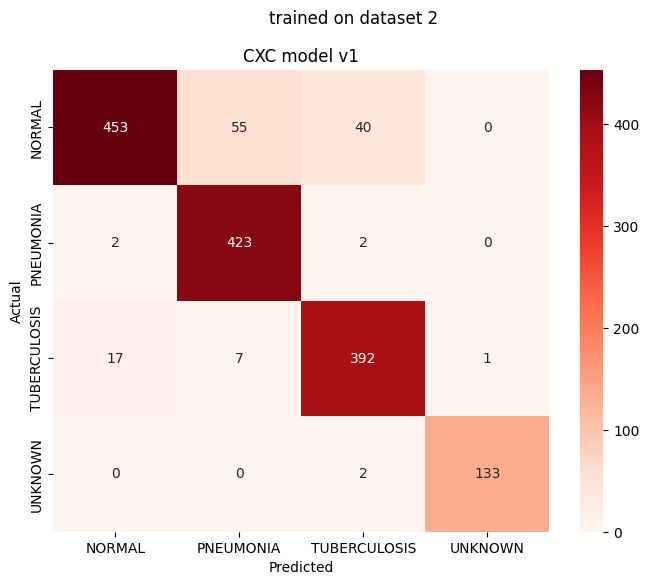

              precision    recall  f1-score   support

      NORMAL       0.96      0.83      0.89       548
   PNEUMONIA       0.87      0.99      0.93       427
TUBERCULOSIS       0.90      0.94      0.92       417
     UNKNOWN       0.99      0.99      0.99       135

    accuracy                           0.92      1527
   macro avg       0.93      0.94      0.93      1527
weighted avg       0.92      0.92      0.92      1527



In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [16]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9159 - loss: 1.6275
Test Loss: 1.627536416053772
Test Accuracy: 91.59%
